# Retail Shelf Vegetable Classifier (Track A) — Reproducible EDA & Experiments

End-to-end visual walkthrough of:
1. **Part 1 Forensic EDA & Data Leakage Audit** (`Dataset/` vs `final_dataset/`)
2. **Leak-Free `StratifiedGroupKFold` Split Verification** (`splits/{train,val,test}.csv`)
3. **Store-Domain Augmentations & `MobileNetV3-Large` Training Curves**
4. **Leak-Free Test Evaluation, Confusion Matrix & Error Analysis**
5. **Grad-CAM Attention Audit** (`assets/gradcam_grid.png`)
6. **Bonus 1: Temperature Scaling & `unknown` OOD Threshold Calibration**
7. **Bonus 2: ONNX Export Equivalence, CPU Latency Benchmark & Offline `predict.py` Verification**

In [1]:
import json
import os
from pathlib import Path
import subprocess
import sys

os.environ.setdefault('MPLCONFIGDIR', '/tmp/mplconfig')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Image as IPyImage

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
eda_summary = json.loads((REPO_ROOT / 'artifacts' / 'eda_summary.json').read_text())
metrics = json.loads((REPO_ROOT / 'artifacts' / 'metrics.json').read_text())
train_hist = json.loads((REPO_ROOT / 'artifacts' / 'train_history.json').read_text())
model_cfg = json.loads((REPO_ROOT / 'models' / 'config.json').read_text())
print('Loaded project artifacts from:', REPO_ROOT)

Loaded project artifacts from: /Users/nurlybekov/Desktop/dev/magnum-veg-cv


## 1. Forensic Dataset Audit & Cross-Split Leakage in `final_dataset/`

We inspect all **3,879** raw images in `Dataset/` alongside the **5,380** files distributed across `final_dataset/{train,val,test}`.

In [2]:
cls_rows = []
for cls_name, info in eda_summary['dataset_eda']['per_class_details'].items():
    leak_info = eda_summary['final_dataset_leakage_audit']['test_vs_train']['per_class'][cls_name]
    cls_rows.append({
        'Class': cls_name,
        'Dataset Count': info['count'],
        'Share (%)': info['pct'],
        'Video Frames (200x200)': info['video_frames'],
        'Mobile Stills (10MP/12MP)': info['mobile_stills'],
        'Unique Video Clips': info['unique_video_clips'],
        'Brightness Mean': info['brightness_mean'],
        'Contrast Mean': info['contrast_mean'],
        'final_dataset/test Leaked (%)': leak_info['leakage_pct'],
    })
df_eda = pd.DataFrame(cls_rows)
display(df_eda)

tvt = eda_summary['final_dataset_leakage_audit']['test_vs_train']
print(f"EXIF-rotated mobile stills: {eda_summary['dataset_eda']['exif_rotated_images']} / {eda_summary['dataset_eda']['mobile_stills_total']} ({eda_summary['dataset_eda']['exif_rotated_among_stills_pct']}%)")
print(f"Consecutive video frame median dHash: {eda_summary['dataset_eda']['sequential_frame_analysis']['consecutive_frame_dhash_median']} vs random same-class median dHash: {eda_summary['dataset_eda']['sequential_frame_analysis']['random_same_class_dhash_median']}")
print(f"final_dataset/test -> train leakage: {tvt['total_exact_or_near_leaked']} / {tvt['total_images']} ({tvt['total_exact_or_near_leaked_pct']}%) [Exact MD5: {tvt['exact_md5_in_train']}, Near-dup only: {tvt['near_duplicate_only_in_train']}]")

EXIF-rotated mobile stills: 175 / 185 (94.59%)
Consecutive video frame median dHash: 5.0 vs random same-class median dHash: 29.0
final_dataset/test -> train leakage: 769 / 799 (96.25%) [Exact MD5: 717, Near-dup only: 52]


Class,Dataset Count,Share (%),Video Frames (200x200),Mobile Stills (10MP/12MP),Unique Video Clips,Brightness Mean,Contrast Mean,final_dataset/test Leaked (%)
Capsicum,615,15.85,573,42,3,104.86,52.64,92.31
Carrot,905,23.33,880,25,6,107.82,53.62,96.05
Cucumber,308,7.94,293,15,2,96.55,53.76,94.83
Potato,422,10.88,376,46,2,111.42,53.65,99.12
Raddish,286,7.37,260,26,2,94.79,62.96,97.47
Squash,1343,34.62,1312,31,4,108.90,60.75,96.85


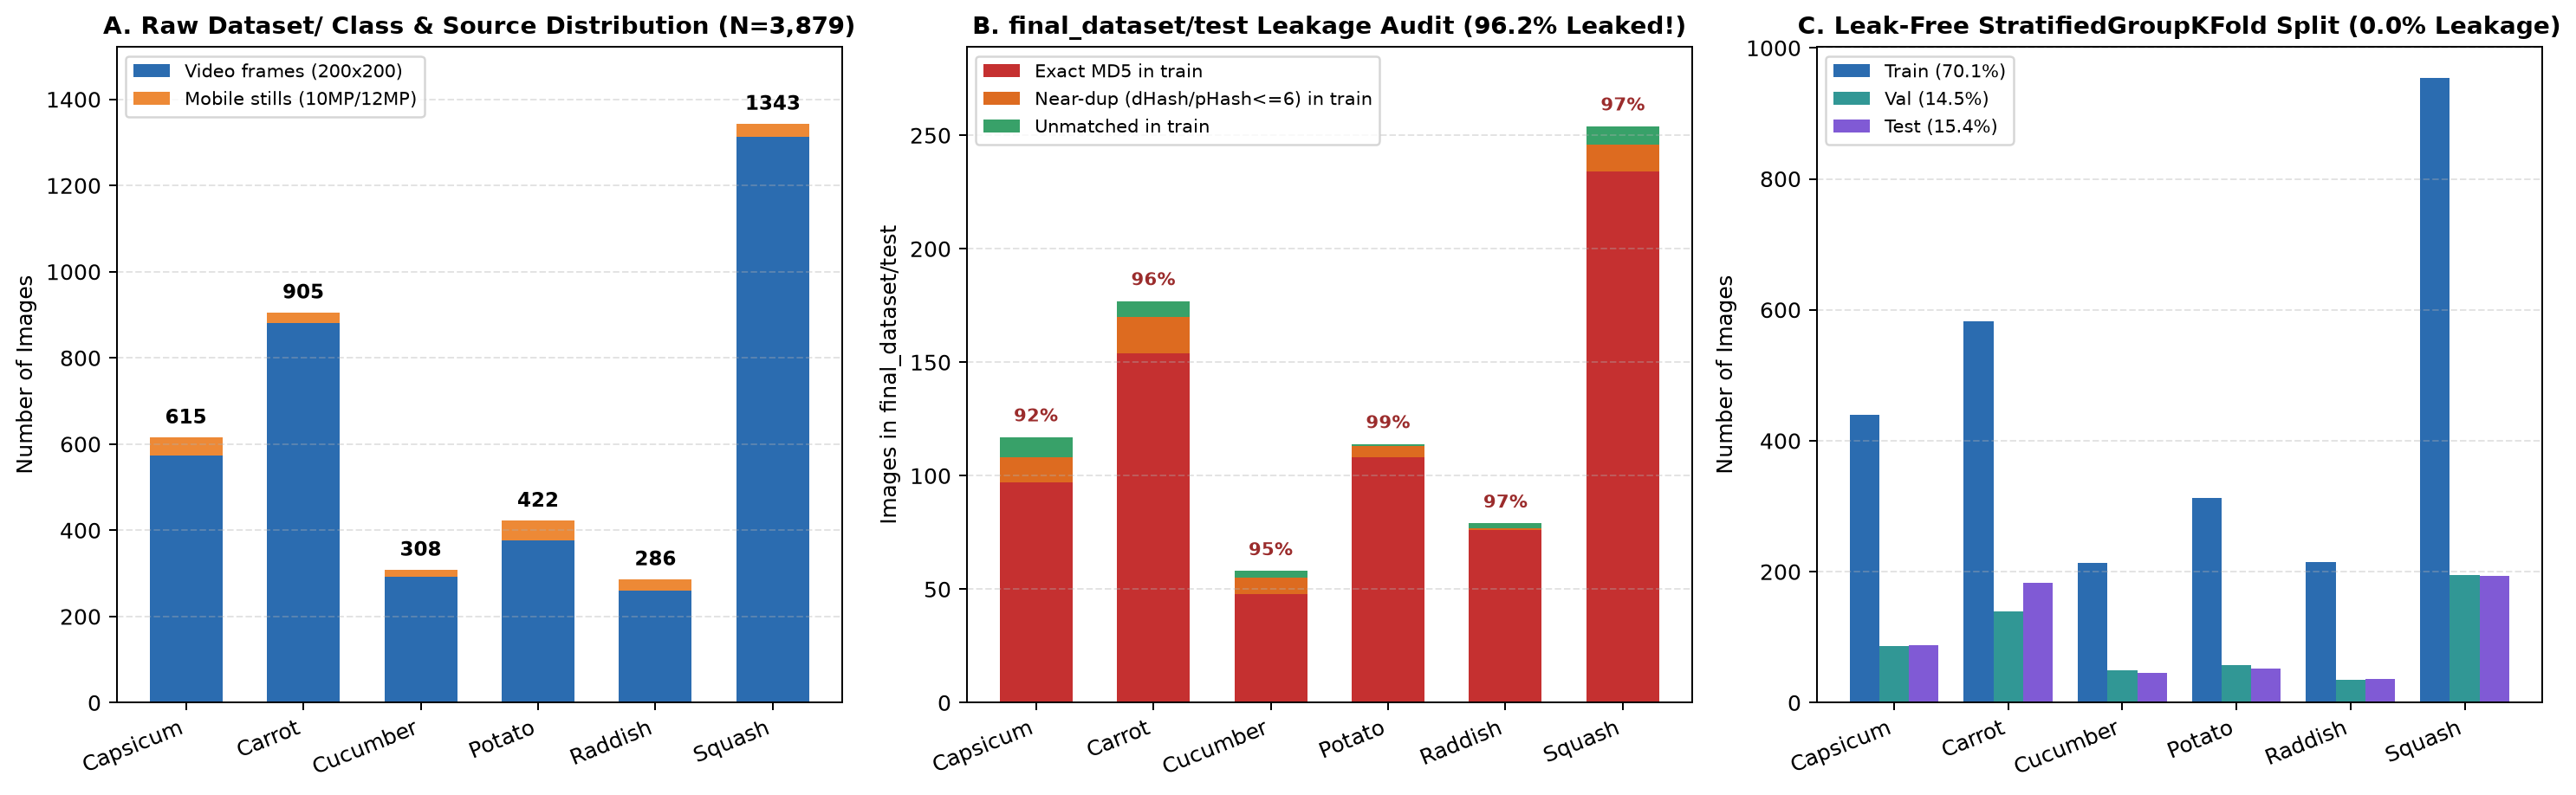

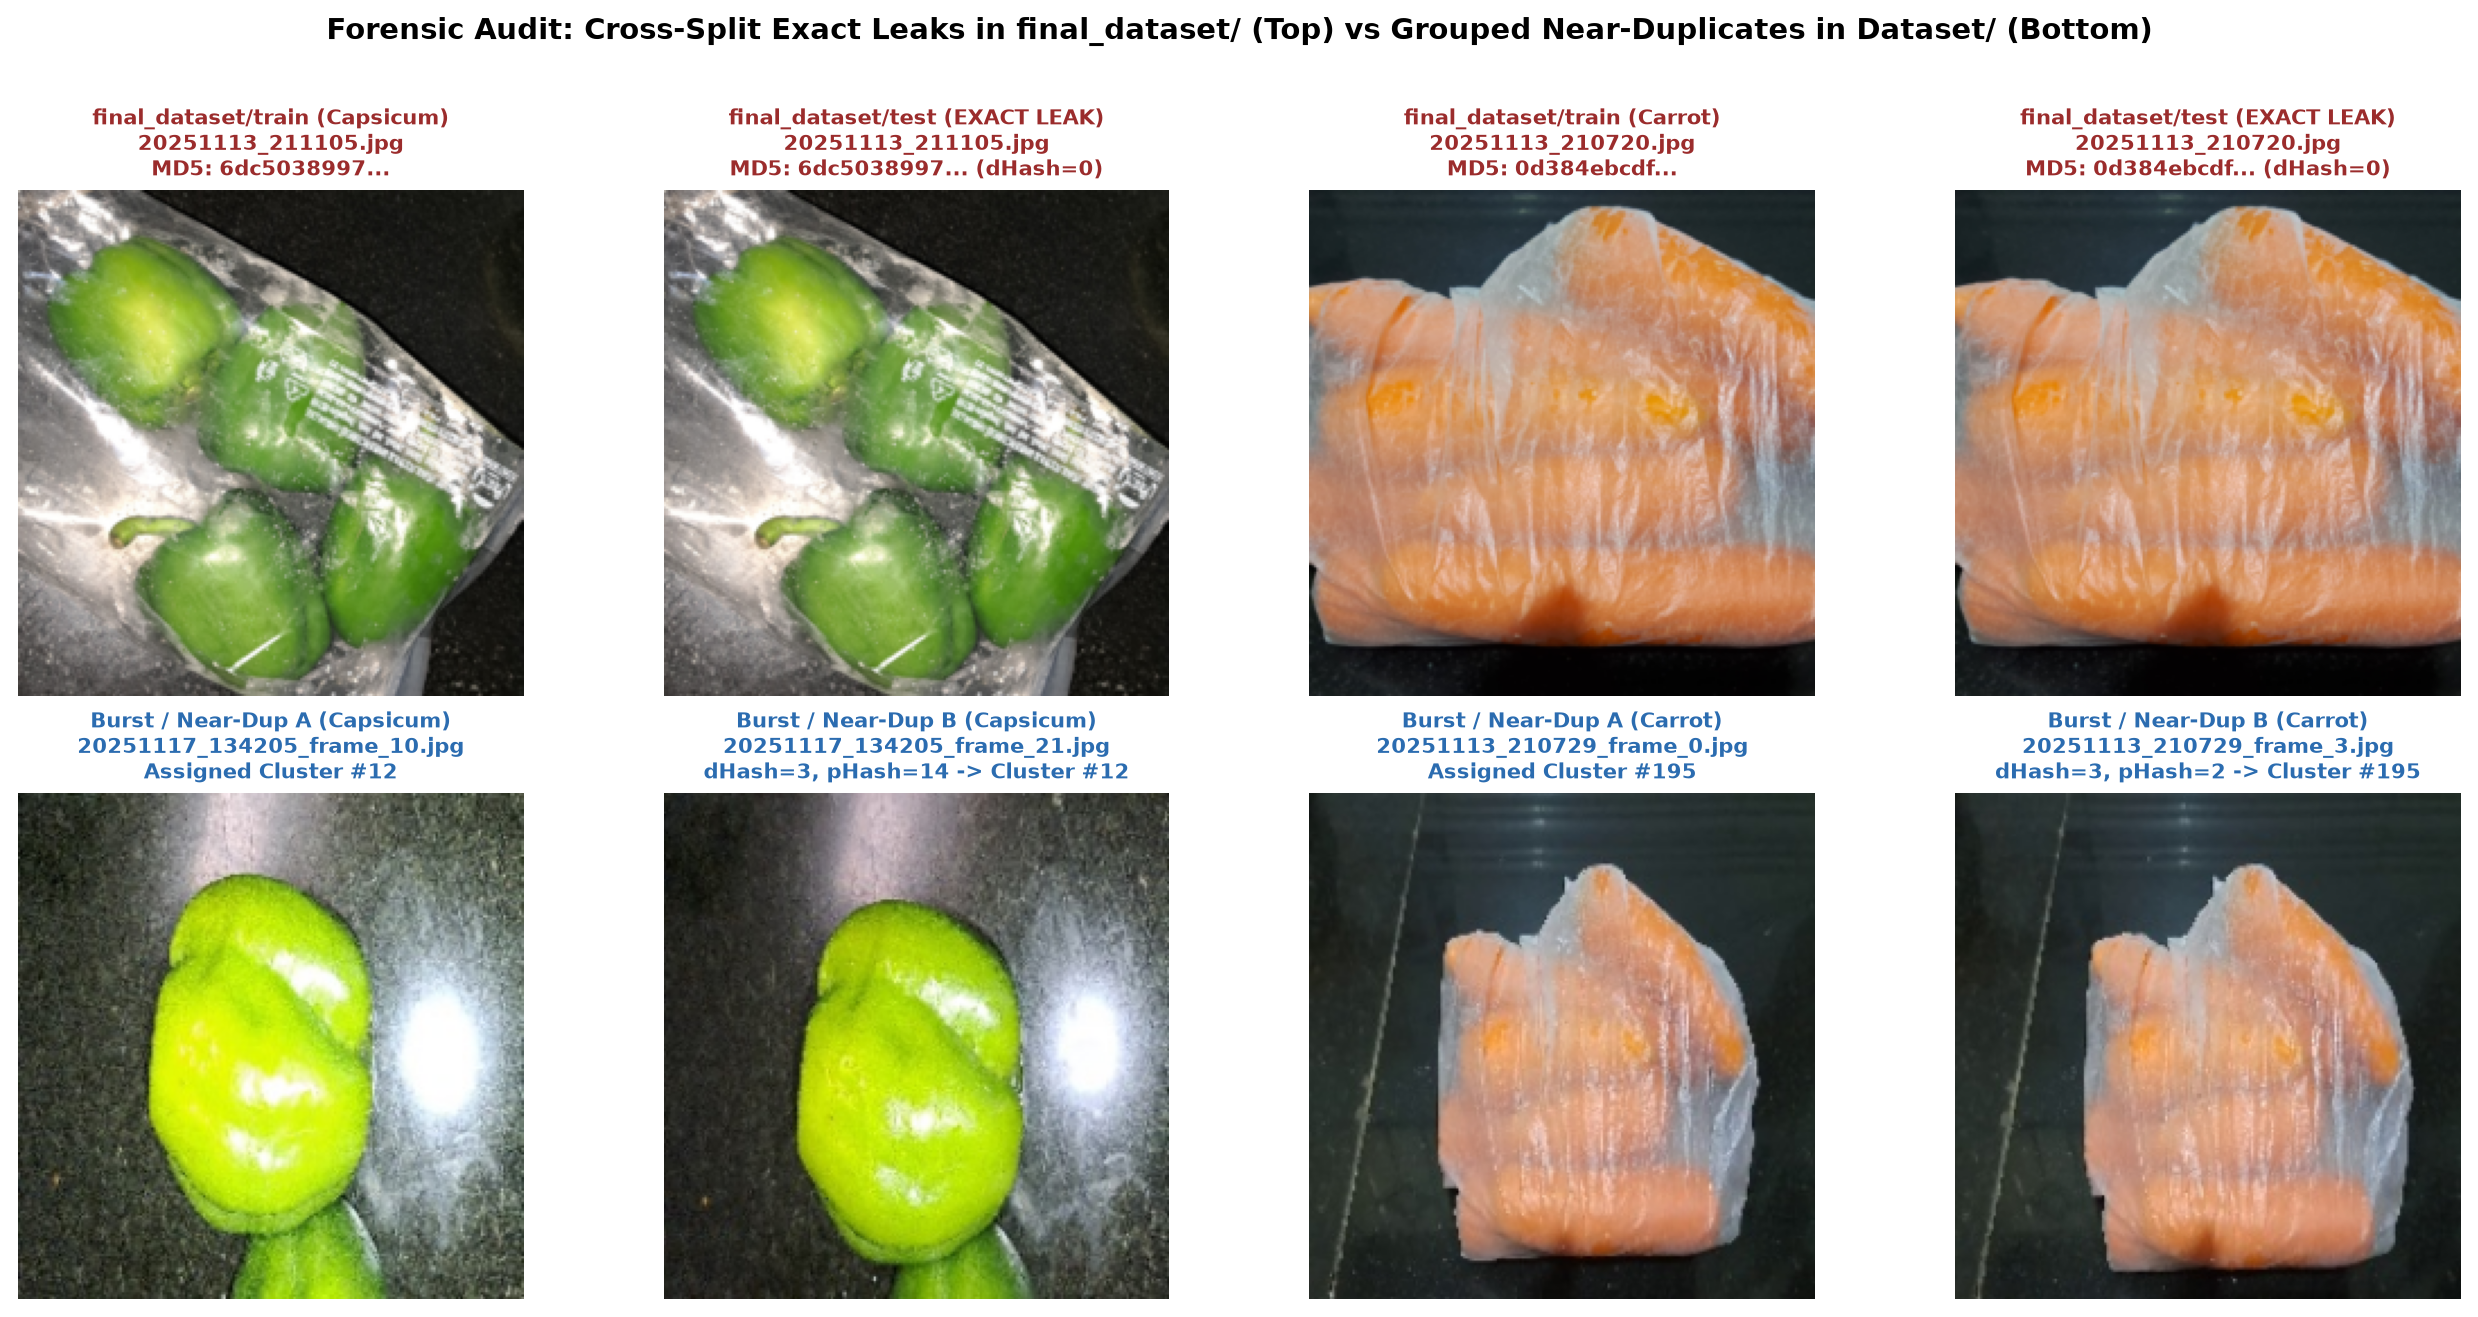

In [3]:
display(IPyImage(filename=str(REPO_ROOT / 'assets' / 'class_distribution.png')))
display(IPyImage(filename=str(REPO_ROOT / 'assets' / 'duplicates_examples.png')))

## 2. Leak-Free `StratifiedGroupKFold` Split Verification (`70 / 15 / 15`)

Grouping exact duplicates, perceptual near-duplicates (`dHash <= 6` or `pHash <= 6`), high-similarity patch embeddings, and adjacent video burst frames via Union-Find yields **972 connected clusters**, partitioned without overlap across `train`, `val`, and `test`.

In [4]:
train_df = pd.read_csv(REPO_ROOT / 'splits' / 'train.csv')
val_df = pd.read_csv(REPO_ROOT / 'splits' / 'val.csv')
test_df = pd.read_csv(REPO_ROOT / 'splits' / 'test.csv')

assert set(train_df['md5']).isdisjoint(val_df['md5'])
assert set(train_df['md5']).isdisjoint(test_df['md5'])
assert set(val_df['md5']).isdisjoint(test_df['md5'])
assert set(train_df['cluster_id']).isdisjoint(val_df['cluster_id'])
assert set(train_df['cluster_id']).isdisjoint(test_df['cluster_id'])
assert set(val_df['cluster_id']).isdisjoint(test_df['cluster_id'])

split_table = pd.DataFrame([
    {
        'Split': sp.upper(),
        'Images': info['count'],
        'Share (%)': info['ratio_pct'],
        'Isolated Clusters': info['unique_clusters'],
        **info['class_counts'],
    }
    for sp, info in eda_summary['clean_split']['splits'].items()
])
display(split_table)
print('Verified zero MD5 overlap and zero cluster overlap across train / val / test.')

Verified zero MD5 overlap and zero cluster overlap across train / val / test.


Split,Images,Share (%),Isolated Clusters,Capsicum,Carrot,Cucumber,Potato,Raddish,Squash
TRAIN,2718,70.07,667,440,583,214,312,215,954
VAL,563,14.51,155,87,139,49,58,35,195
TEST,598,15.42,150,88,183,45,52,36,194


## 3. Store-Domain Augmentations & `MobileNetV3-Large` Training Summary

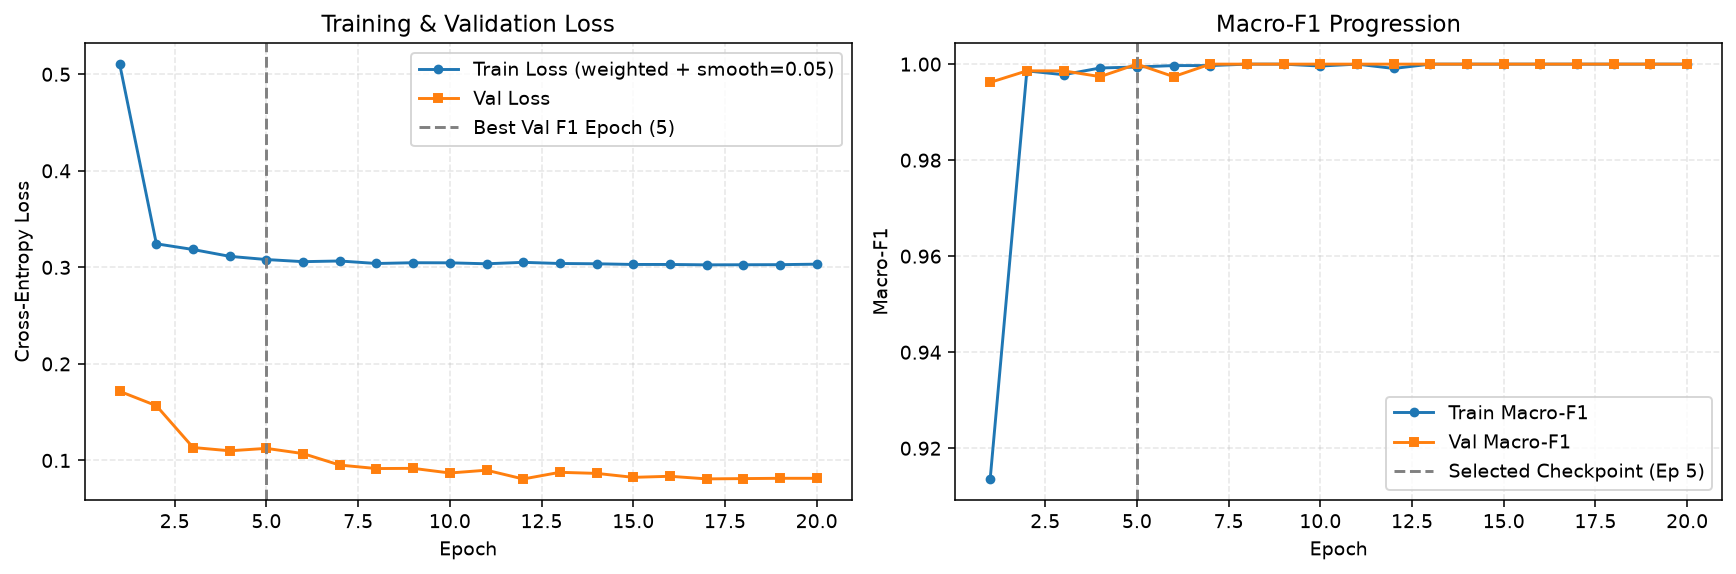

In [5]:
hist_df = pd.DataFrame(train_hist['history'])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), dpi=140)
axes[0].plot(hist_df['epoch'], hist_df['train_loss'], marker='o', markersize=4, label='Train Loss (weighted + smooth=0.05)')
axes[0].plot(hist_df['epoch'], hist_df['val_loss'], marker='s', markersize=4, label='Val Loss')
axes[0].axvline(train_hist['best_epoch'], linestyle='--', color='gray', label=f"Best Val F1 Epoch ({train_hist['best_epoch']})")
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-Entropy Loss'); axes[0].set_title('Training & Validation Loss')
axes[0].legend(); axes[0].grid(alpha=0.3, linestyle='--')

axes[1].plot(hist_df['epoch'], hist_df['train_macro_f1'], marker='o', markersize=4, label='Train Macro-F1')
axes[1].plot(hist_df['epoch'], hist_df['val_macro_f1'], marker='s', markersize=4, label='Val Macro-F1')
axes[1].axvline(train_hist['best_epoch'], linestyle='--', color='gray', label=f"Selected Checkpoint (Ep {train_hist['best_epoch']})")
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Macro-F1'); axes[1].set_title('Macro-F1 Progression')
axes[1].legend(); axes[1].grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

## 4. Leak-Free Test Evaluation, Confusion Matrix & Error Analysis

Test Accuracy: 0.9950 | Test Macro-F1: 0.9950 | Misclassified: 3/598
Simulated Store-Stress Accuracy: 0.9967 | Store-Stress Macro-F1: 0.9959

Misclassified test samples (all low-confidence overexposed flash frames):


Class,precision,recall,f1,support
Capsicum,1.0000,1.0000,1.0000,88.0
Carrot,1.0000,0.9836,0.9917,183.0
Cucumber,1.0000,1.0000,1.0000,45.0
Potato,0.9630,1.0000,0.9811,52.0
Raddish,1.0000,1.0000,1.0000,36.0
Squash,0.9949,1.0000,0.9974,194.0


filepath,true_label,pred_label,confidence,true_class_prob
data/Dataset/Dataset/Carrot/20251113_210803_frame_10.jpg,Carrot,Potato,0.2978,0.2057
data/Dataset/Dataset/Carrot/20251113_210803_frame_11.jpg,Carrot,Potato,0.3111,0.1711
data/Dataset/Dataset/Carrot/20251113_210803_frame_12.jpg,Carrot,Squash,0.2597,0.2295


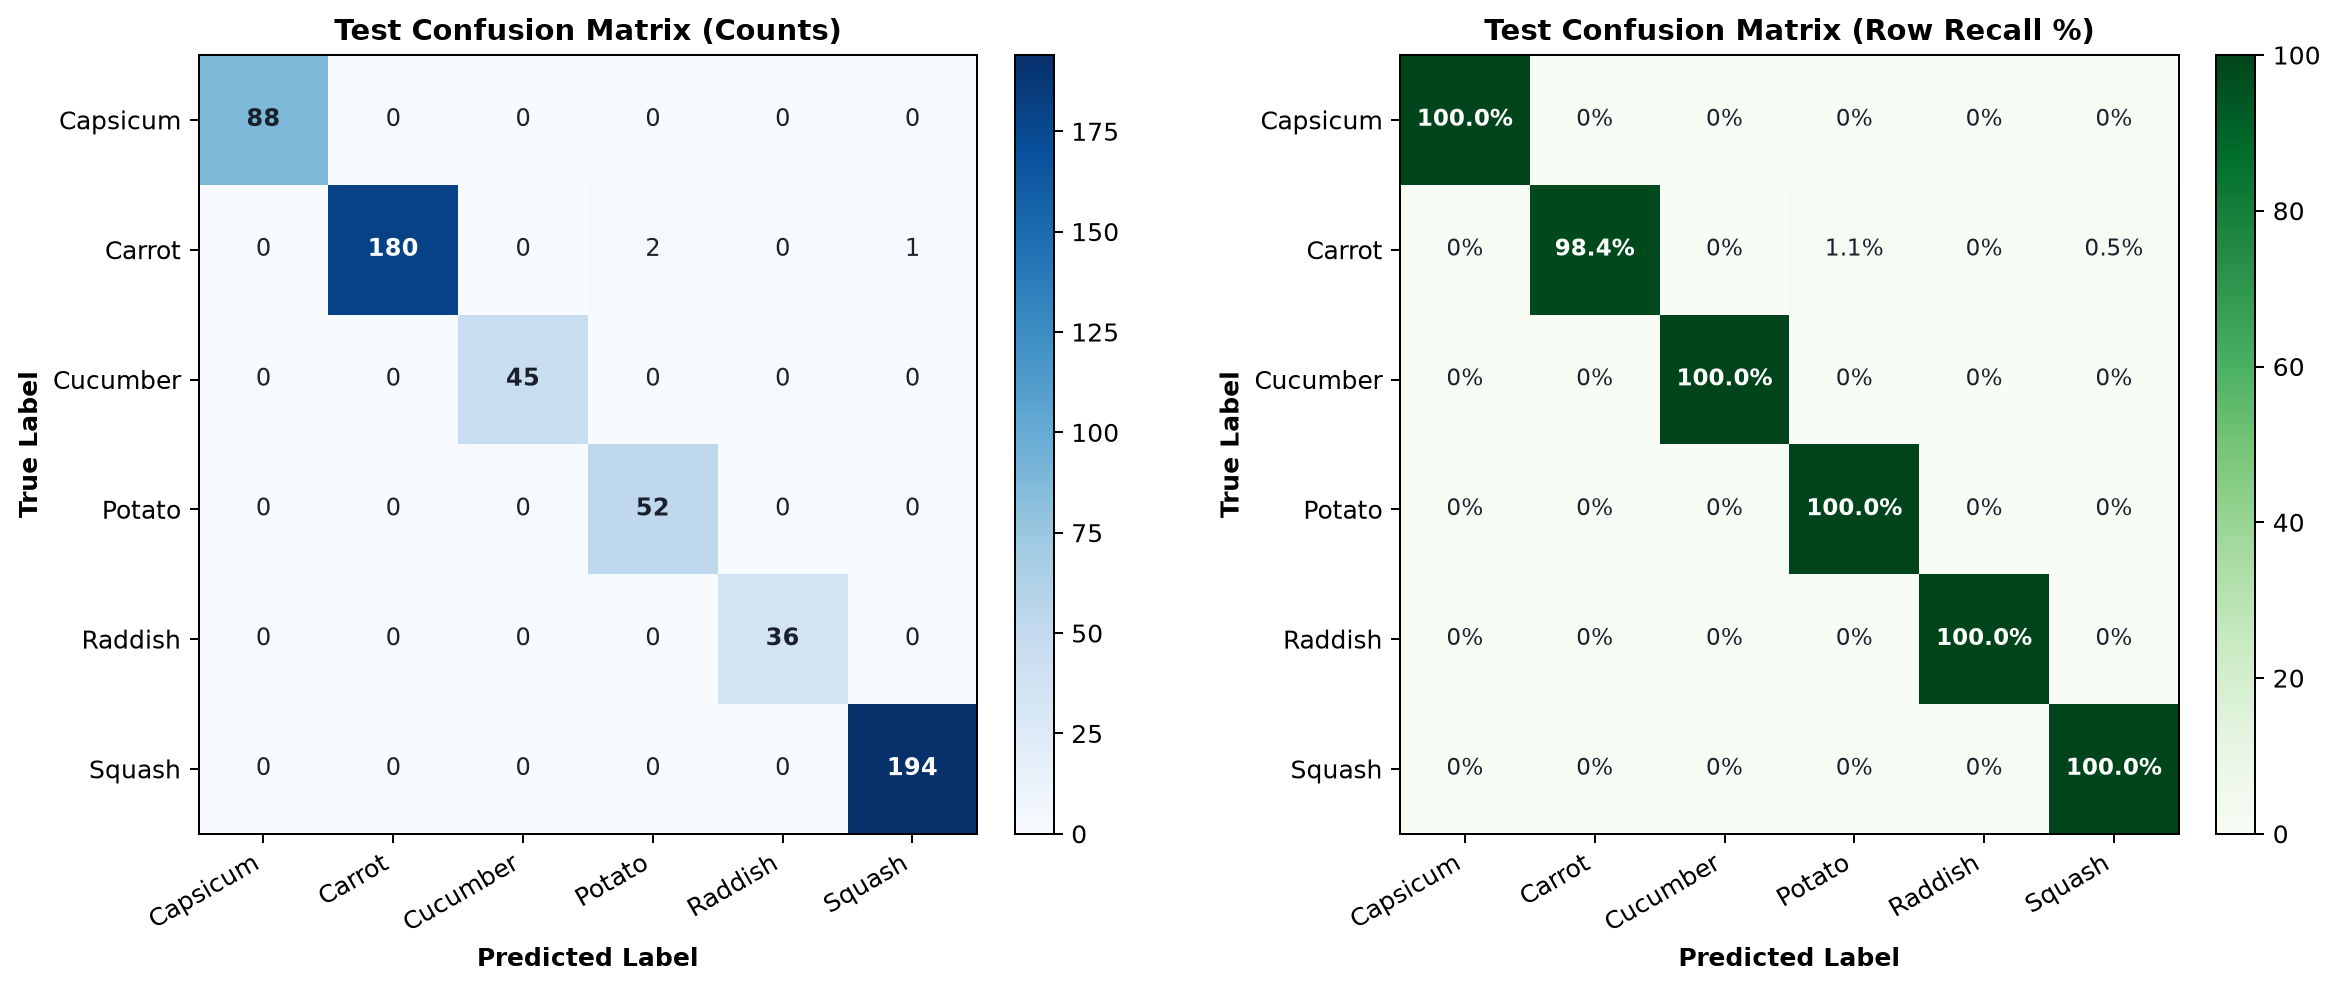

In [6]:
te = metrics['test_evaluation']
per_cls_df = pd.DataFrame(te['per_class']).T.reset_index().rename(columns={'index': 'Class'})
display(per_cls_df)
print(f"Test Accuracy: {te['accuracy']:.4f} | Test Macro-F1: {te['macro_f1']:.4f} | Misclassified: {te['misclassified_count']}/{te['num_samples']}")
print(f"Simulated Store-Stress Accuracy: {te['store_augmented_stress_accuracy']:.4f} | Store-Stress Macro-F1: {te['store_augmented_stress_macro_f1']:.4f}")
print('\nMisclassified test samples (all low-confidence overexposed flash frames):')
display(pd.DataFrame(te['misclassified_examples']))
display(IPyImage(filename=str(REPO_ROOT / 'assets' / 'confusion_matrix.png')))

## 5. Grad-CAM Attention Audit (`model.features[-1]`)

In 7/8 inspected samples (mean center/border activation ratio 1.53x on confident correct vs 2.43x on misclassified/edge cases), Grad-CAM activations concentrate on vegetable skin texture, ridges, stems, and contours rather than the dark countertop; on edge/misclassified frames with polythene glare or partial crops, attention partially spills onto specular highlights and bag/border boundaries.


category,true_label,pred_label,confidence,entropy,center_vs_border_activation_ratio,focuses_on_foreground
Confident Correct,Raddish,Raddish,0.9889,0.0747,1.353,True
Confident Correct,Cucumber,Cucumber,0.9795,0.1294,1.949,True
Confident Correct,Potato,Potato,0.9652,0.2001,1.438,True
Confident Correct,Capsicum,Capsicum,0.9600,0.2303,1.389,True
Misclassified,Carrot,Potato,0.3111,1.5700,3.403,True
Misclassified,Carrot,Potato,0.2978,1.5820,2.867,True
Misclassified,Carrot,Squash,0.2597,1.5912,0.710,False
Low-Conf Edge Case,Capsicum,Capsicum,0.7518,0.9097,2.758,True


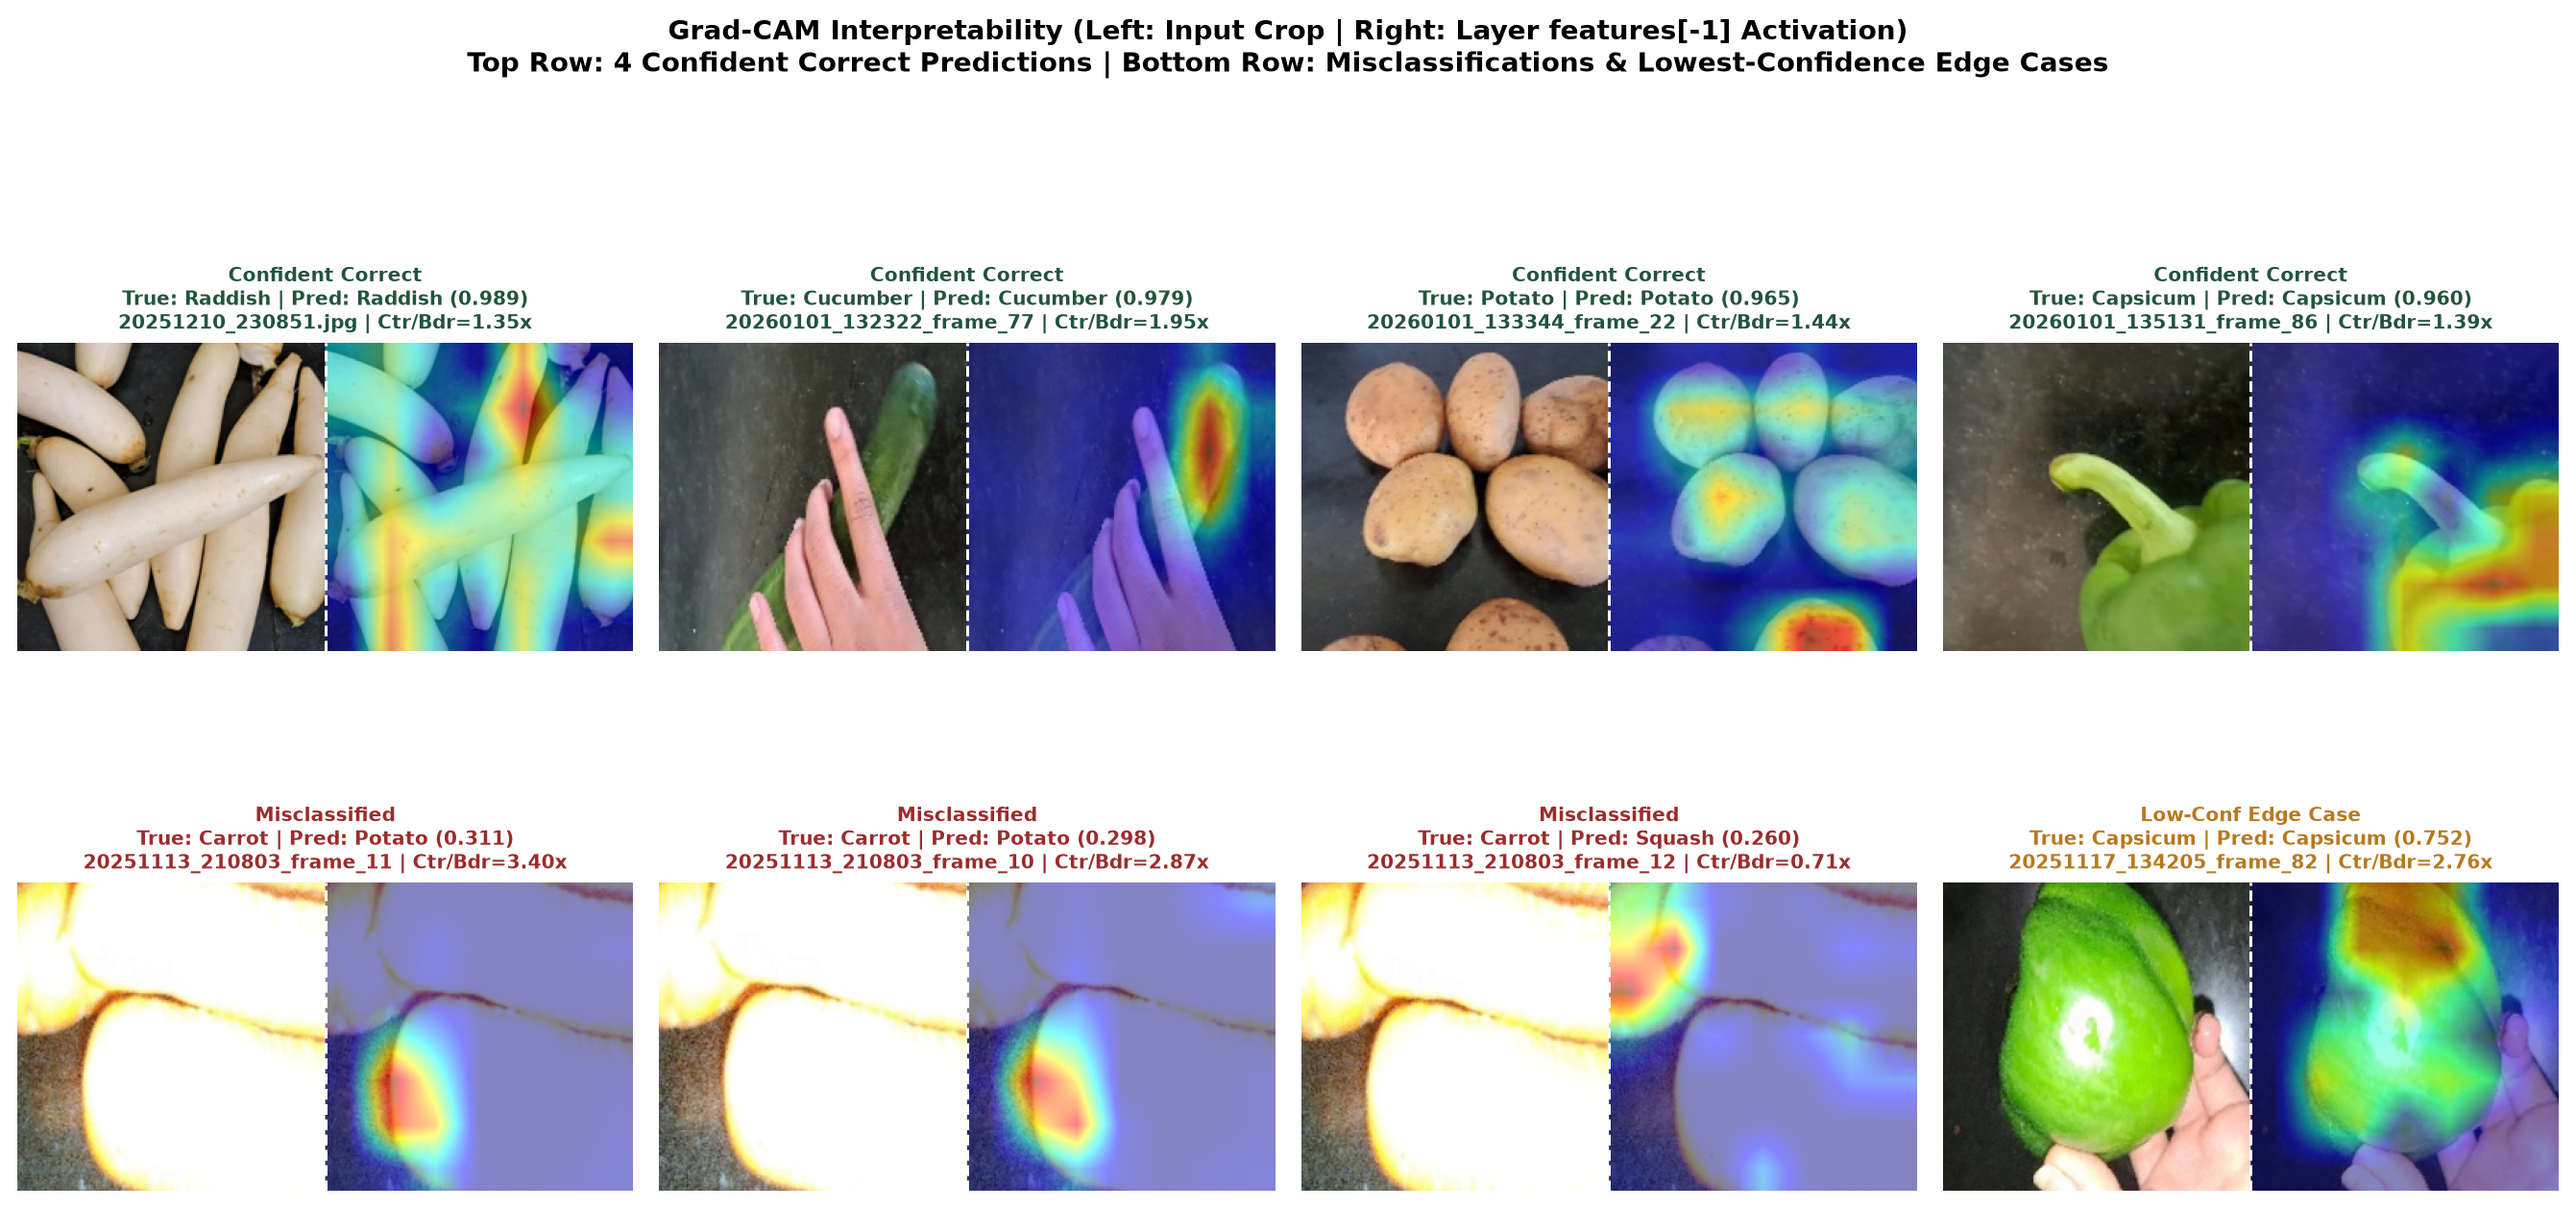

In [7]:
gc = metrics['gradcam']
print(gc['attention_assessment'])
display(pd.DataFrame(gc['samples'])[['category', 'true_label', 'pred_label', 'confidence', 'entropy', 'center_vs_border_activation_ratio', 'focuses_on_foreground']])
display(IPyImage(filename=str(REPO_ROOT / 'assets' / 'gradcam_grid.png')))

## 6. Bonus 1: Temperature Scaling & `unknown` OOD Calibration

Calibrated Temperature T = 0.7231 | Unknown Threshold = 0.89
ECE before -> after: 0.1031 -> 0.0316
Clean ID Retention: 99.47% | Combined ID Retention: 99.02% | OOD Rejection: 100.0% | AUROC: 0.999


OOD Rejection (%)
100.0
100.0
100.0
100.0
100.0
100.0


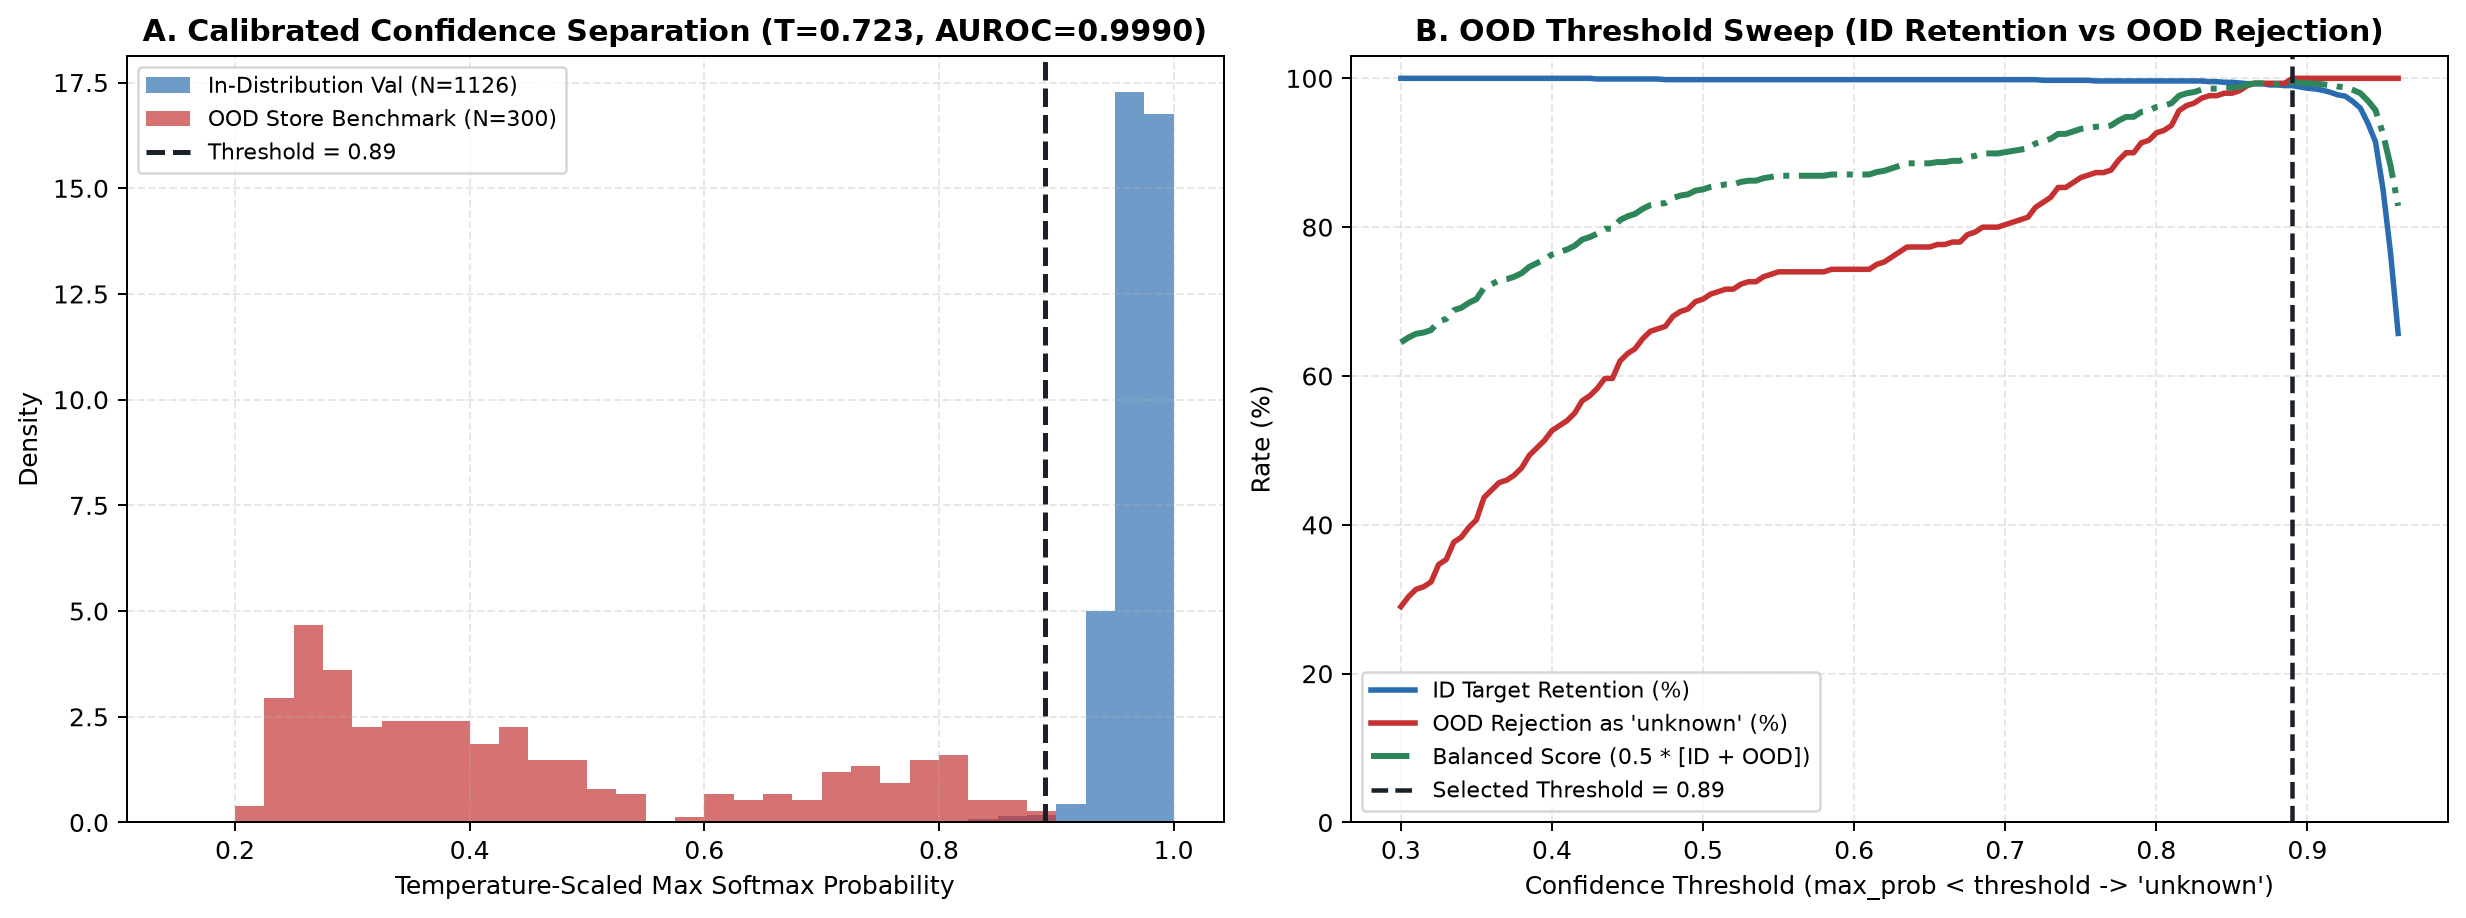

In [8]:
ood = metrics['ood_calibration']
print(f"Calibrated Temperature T = {ood['temperature']} | Unknown Threshold = {ood['unknown_threshold']}")
print(f"ECE before -> after: {ood['calibration_stats']['ece_before']} -> {ood['calibration_stats']['ece_after']}")
print(f"Clean ID Retention: {ood['clean_val_id_retention_pct']}% | Combined ID Retention: {ood['combined_val_id_retention_pct']}% | OOD Rejection: {ood['ood_rejection_pct']}% | AUROC: {ood['auroc_id_vs_ood']}")
display(pd.DataFrame([ood['per_category_ood_rejection_pct']]).T.rename(columns={0: 'OOD Rejection (%)'}))
display(IPyImage(filename=str(REPO_ROOT / 'assets' / 'ood_threshold_curve.png')))

## 7. Bonus 2: ONNX Export, CPU Latency Benchmark & `predict.py` Verification

In [9]:
ox = metrics['onnx_export']
bench_df = pd.DataFrame([
    {'Runtime': 'PyTorch CPU (B=1)', **ox['benchmark']['pytorch_cpu_ms']},
    {'Runtime': 'ONNX Runtime CPU (B=1)', **ox['benchmark']['onnx_cpu_ms']},
])
display(bench_df)
print(f"ONNX Size: {ox['size_mb']} MB | Max |PT - ONNX| diff: {ox['max_abs_diff_vs_pytorch']:.2e} | Mean CPU Speedup: {ox['benchmark']['speedup_mean_x']}x")

tmp_preds = Path('/tmp/nb_test_verify_preds.csv')
sample_folder = REPO_ROOT / 'artifacts' / 'ood_benchmark'
subprocess.run([sys.executable, str(REPO_ROOT / 'predict.py'), '--input', str(sample_folder), '--output', str(tmp_preds)], check=True)
preds_sample_df = pd.read_csv(tmp_preds)
print(f"predict.py on 300 OOD benchmark images -> {(preds_sample_df['label'] == 'unknown').mean()*100:.2f}% labeled 'unknown'")
display(preds_sample_df.head(6))

ONNX Size: 16.05 MB | Max |PT - ONNX| diff: 3.64e-06 | Mean CPU Speedup: 15.23x
predict.py on 300 OOD benchmark images -> 100.00% labeled 'unknown'


Runtime,mean,std,p50,p95
PyTorch CPU (B=1),39.629,1.126,39.299,41.075
ONNX Runtime CPU (B=1),2.602,0.195,2.542,3.031


filename,label,confidence
ood_camera_fault_000.jpg,unknown,0.3631
ood_camera_fault_001.jpg,unknown,0.4330
ood_camera_fault_002.jpg,unknown,0.2362
ood_camera_fault_003.jpg,unknown,0.3850
ood_camera_fault_004.jpg,unknown,0.4314
ood_camera_fault_005.jpg,unknown,0.2942
